# 03a — Summary statistics on the regenerated data (System I, N3)

Sections 1–9 of the old notebook 03 (M3) on the data of the N3 re-run; notebook 03 itself, with its section 10 (the summary-set decision S0 → S1), is left untouched. **D0** (`observations.npz`: Sc0–Sc7 × 50, nominal inlet, P2, N3 sensors) gives the 29 base summaries and,
with the three plug-in estimators, the naive set S1 (32). **D1** (Sc1–Sc5 and Sc7 × 50, measured inlet) gives the production set **S1m** (34: the 29 base summaries, the three plug-in estimators computed with the *measured* inlet, and the two measured temperatures minus 297 K).

**Content (descriptive; no decision rule; runbook §2f row g-03):** per-scenario feature heatmap; PCA and t-SNE of the standardised D0 features; mutual-information ranking with the scenario label (D0 29 features; D1 34); 5-fold LDA accuracy by feature group (the ablation of the old §6); the saturation-fraction features
(the old text said only Sc5 saturates; with the inlet varying more scenarios do); the plug-in estimators against the truth. **Checks:** finite; 50 windows per scenario; the standardised features have no constant column among the 29 base features of D0 except those listed.


In [1]:
import os, sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
NB_DIR = Path.cwd().resolve()
assert NB_DIR.name == "system_I" and NB_DIR.parent.name == "notebooks", f"run from notebooks/system_I (cwd {NB_DIR})"
ROOT = NB_DIR.parent.parent
for p in (ROOT / "src", ROOT / "scripts"):
    sys.path.insert(0, str(p))
os.environ["CSTR_SENSOR_MODEL"] = "N3"
warnings.filterwarnings("ignore")
import importlib, ws_eval, ws_phase3, summary_variants
for _m in (ws_eval, ws_phase3, summary_variants):
    importlib.reload(_m)
we, P3, sv = ws_eval, ws_phase3, summary_variants
from cstr_sbi.scenarios import SCENARIO_CONFIGS
from cstr_sbi.summaries import FEATURE_GROUPS, feature_indices
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.feature_selection import mutual_info_classif
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import StratifiedKFold
R = ROOT / "results"; FIGS = ROOT / "figures"; FIGS.mkdir(exist_ok=True); T0 = time.time()
BASE = list(sv.BASE29); EST = list(sv.EST); S1M_NAMES = BASE + EST + ["Ti_meas_minus_297", "Tci_meas_minus_297"]
d0, d1 = P3.load_d0(), P3.load_d1()
t = np.asarray(d0["t"], np.float32)
X0 = we.features(d0["x"], t, "S1_base_est")            # (400, 32): 29 base + 3 estimators, nominal inlet
X1 = P3.production_features(d1)                        # (300, 34): S1m
sid0, sid1 = d0["scenario_id"], d1["scenario_id"]
assert np.isfinite(X0).all() and np.isfinite(X1).all() and X0.shape == (400, 32) and X1.shape == (300, 34)
assert all((sid0 == s).sum() == 50 for s in range(8)) and all((sid1 == s).sum() == 50 for s in (1, 2, 3, 4, 5, 7))
name = {s.id: s.name for s in SCENARIO_CONFIGS.values()}
const0 = [BASE[i] for i in range(29) if X0[:, i].std() < 1e-12]
print("D0", X0.shape, "| D1", X1.shape, "| constant base features in D0:", const0)


D0 (400, 32) | D1 (300, 34) | constant base features in D0: []


## 2. Per-scenario feature heatmap (D0, 29 base features, z-scored over the dataset)

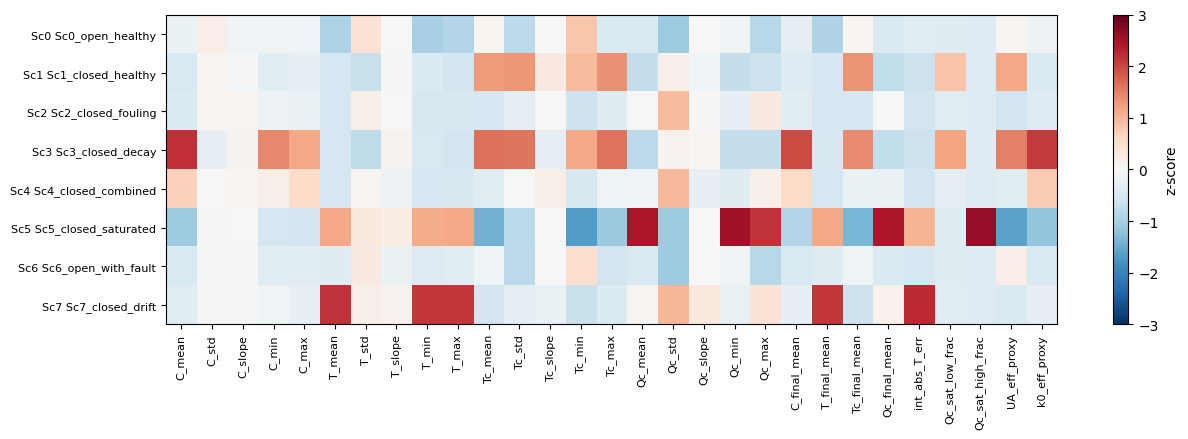

In [2]:
B0 = X0[:, :29]; keep0 = B0.std(0) > 1e-12
Z0 = np.zeros_like(B0); Z0[:, keep0] = StandardScaler().fit_transform(B0[:, keep0])
Zs = pd.DataFrame(Z0, columns=BASE).groupby(sid0).mean()
fig, ax = plt.subplots(figsize=(13, 4.5)); im = ax.imshow(Zs.values, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3)
ax.set_yticks(range(len(Zs))); ax.set_yticklabels([f"Sc{i} {name[i]}" for i in Zs.index], fontsize=8); ax.set_xticks(range(29)); ax.set_xticklabels(BASE, rotation=90, fontsize=8)
fig.colorbar(im, ax=ax, label="z-score"); fig.tight_layout(); fig.savefig(FIGS / "03a_N3_feature_heatmap.png", dpi=140); plt.show()


## 3. PCA and t-SNE of the standardised D0 features

explained variance ratio PC1..5: [0.425 0.125 0.077 0.068 0.065] | cumulative 2: 0.55
PC1 top loadings: [('Tc_mean', 0.26), ('UA_eff_proxy', 0.26), ('Qc_mean', -0.25), ('Qc_final_mean', -0.25), ('Tc_final_mean', 0.25), ('Tc_min', 0.25)]
PC2 top loadings: [('T_min', 0.33), ('T_final_mean', 0.33), ('T_mean', 0.33), ('T_max', 0.31), ('int_abs_T_err', 0.29), ('Tc_std', 0.25)]


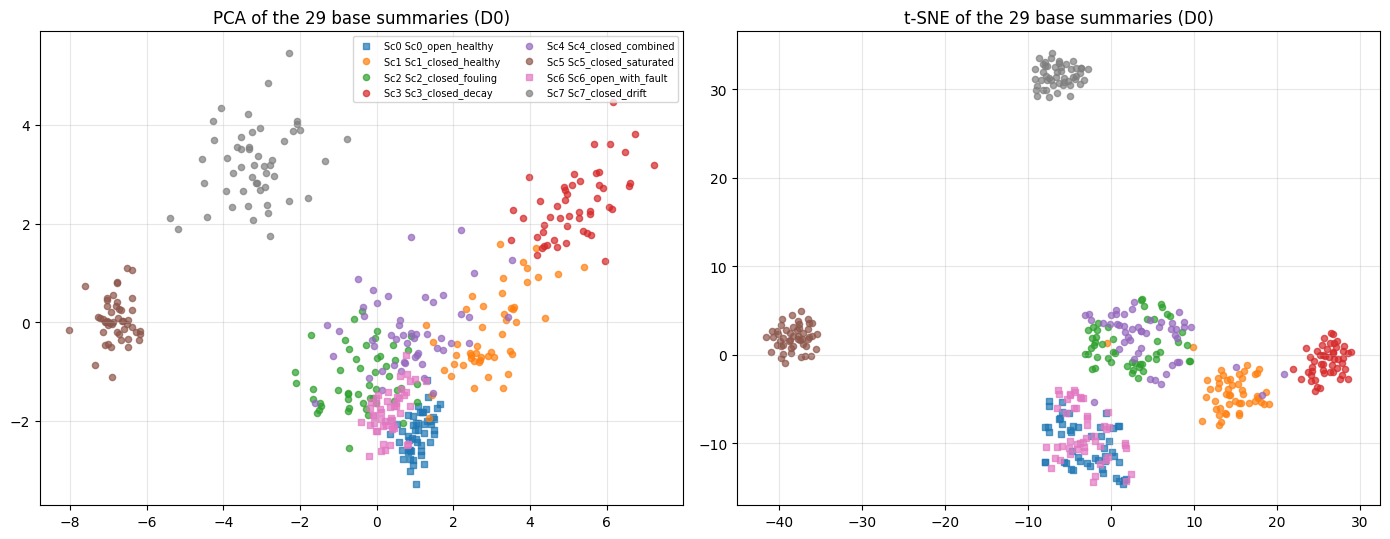

In [3]:
pca = PCA(n_components=5).fit(Z0); Y = pca.transform(Z0)
print("explained variance ratio PC1..5:", np.round(pca.explained_variance_ratio_, 3), "| cumulative 2:", round(float(pca.explained_variance_ratio_[:2].sum()), 3))
for k in range(2):
    o = np.argsort(-np.abs(pca.components_[k]))[:6]; print(f"PC{k+1} top loadings:", [(BASE[i], round(float(pca.components_[k, i]), 2)) for i in o])
tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=0, learning_rate="auto").fit_transform(Z0)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5)); cm = plt.get_cmap("tab10")
for k, (E_, ttl) in enumerate(((Y, "PCA"), (tsne, "t-SNE"))):
    for s in sorted(set(sid0)):
        m = sid0 == s; ax[k].scatter(E_[m, 0], E_[m, 1], s=20, alpha=.7, color=cm(s), marker="o" if d0["mode"][m][0] == "closed_loop" else "s", label=f"Sc{s} {name[s]}")
    ax[k].set_title(ttl + " of the 29 base summaries (D0)"); ax[k].grid(alpha=.3)
ax[0].legend(fontsize=7, ncol=2); fig.tight_layout(); fig.savefig(FIGS / "03a_N3_pca_tsne.png", dpi=140); plt.show()


## 4. Mutual information with the scenario label: D0 (29 base features) and D1 (34 production features)

In [4]:
mi0 = mutual_info_classif(Z0[:, keep0], sid0, random_state=0); n0 = [BASE[i] for i in np.where(keep0)[0]]
Z1 = StandardScaler().fit_transform(X1); mi1 = mutual_info_classif(Z1, sid1, random_state=0)
t0 = pd.DataFrame(dict(feature=n0, mi=mi0)).sort_values("mi", ascending=False); t1 = pd.DataFrame(dict(feature=S1M_NAMES, mi=mi1)).sort_values("mi", ascending=False)
print("D0, top 10:"); display(t0.head(10).round(3).reset_index(drop=True)); print("D1 (S1m), top 10:"); display(t1.head(10).round(3).reset_index(drop=True))
t0.to_csv(R / "03a_N3_mi_D0.csv", index=False); t1.to_csv(R / "03a_N3_mi_D1_S1m.csv", index=False)


D0, top 10:


,feature,mi
0,Tc_mean,1.385
1,UA_eff_proxy,1.285
2,Tc_final_mean,1.225
3,T_mean,1.219
4,Qc_mean,1.175
5,Qc_max,1.173
6,Tc_max,1.163
7,Qc_final_mean,1.152
8,Qc_min,1.112
9,Tc_min,1.111


D1 (S1m), top 10:


,feature,mi
0,ln_beta_hat_rx,1.042
1,ln_alpha_hat,0.880
2,k0_eff_proxy,0.813
3,C_mean,0.812
4,C_final_mean,0.611
5,T_max,0.559
6,int_abs_T_err,0.553
7,T_min,0.548
8,T_mean,0.489
9,ln_beta_hat_jac,0.475


## 5. LDA ablation by feature group (5-fold, scenario label)

In [5]:
def cv(Z, y, idx):
    sk = StratifiedKFold(5, shuffle=True, random_state=0)
    return float(np.mean([LinearDiscriminantAnalysis().fit(Z[tr][:, idx], y[tr]).score(Z[te][:, idx], y[te]) for tr, te in sk.split(Z, y)]))
rows = [("D0: all 29 base", 29, cv(Z0[:, keep0], sid0, np.arange(keep0.sum())))]
names0 = np.array(BASE)[keep0]
for g, nm in FEATURE_GROUPS.items():
    if g == "all": continue
    idx = [i for i, n in enumerate(names0) if n in nm]
    if idx: rows.append((f"D0: group {g}", len(idx), cv(Z0[:, keep0], sid0, np.array(idx))))
for K in (5, 10, 15):
    o = [n0.index(f) for f in t0.feature.head(K)]; rows.append((f"D0: top-{K} MI", K, cv(Z0[:, keep0], sid0, np.array(o))))
nm1 = np.array(S1M_NAMES)
for lab, sel in (("D1: base 29", BASE), ("D1: base + 3 estimators", BASE + EST), ("D1: S1m (34)", S1M_NAMES), ("D1: estimators + measured temperatures only", EST + S1M_NAMES[-2:])):
    rows.append((lab, len(sel), cv(Z1, sid1, np.array([list(nm1).index(f) for f in sel]))))
abl = pd.DataFrame(rows, columns=["subset", "n_features", "lda_cv_accuracy"]); display(abl.round(3)); abl.to_csv(R / "03a_N3_lda_ablation.csv", index=False)


,subset,n_features,lda_cv_accuracy
0,D0: all 29 base,29,0.982
1,D0: group per_channel,20,0.972
2,D0: group final_window,4,0.830
3,D0: group aggregates,3,0.540
4,D0: group physics,2,0.715
5,D0: group compact,12,0.962
6,D0: group means_only,4,0.950
7,D0: top-5 MI,5,0.772
8,D0: top-10 MI,10,0.788
9,D0: top-15 MI,15,0.985


## 6. Saturation fractions per scenario (D0 nominal inlet against D1 inlet varying)

In [6]:
rows = []
for s in range(8):
    m0 = sid0 == s; r = dict(scenario=f"Sc{s}", D0_high=float(X0[m0, BASE.index("Qc_sat_high_frac")].mean()), D0_low=float(X0[m0, BASE.index("Qc_sat_low_frac")].mean()))
    m1 = sid1 == s
    if m1.any(): r.update(D1_high=float(X1[m1, BASE.index("Qc_sat_high_frac")].mean()), D1_low=float(X1[m1, BASE.index("Qc_sat_low_frac")].mean()))
    rows.append(r)
sat = pd.DataFrame(rows); display(sat.round(3)); sat.to_csv(R / "03a_N3_saturation_fractions.csv", index=False)


,scenario,D0_high,D0_low,D1_high,D1_low
0,Sc0,0.000,0.000,NaN,NaN
1,Sc1,0.000,0.013,0.217,0.071
2,Sc2,0.000,0.000,0.298,0.042
3,Sc3,0.000,0.017,0.076,0.070
4,Sc4,0.000,0.001,0.211,0.061
5,Sc5,0.691,0.000,0.513,0.011
6,Sc6,0.000,0.000,NaN,NaN
7,Sc7,0.000,0.000,0.254,0.049


## 7. The plug-in estimators against the truth (window means: exp of the log-estimate)

In [7]:
rows = []
for lab, X, sid, d in (("D0 (nominal inlet assumed; true inlet nominal)", X0, sid0, d0), ("D1 (S1m: measured inlet in the estimators)", X1, sid1, d1)):
    th = d["theta"]
    for s in sorted(set(sid)):
        m = sid == s
        if d["mode"][m][0] != "closed_loop": continue
        rows.append(dict(data=lab, scenario=f"Sc{s}", alpha_true=float(th[m][0, 2]), beta_true=float(th[m][0, 3]), alpha_hat=float(np.exp(X[m, 29]).mean()),
                         beta_hat_jac=float(np.exp(X[m, 30]).mean()), beta_hat_rx=float(np.exp(X[m, 31]).mean()), sd_ln_alpha=float(X[m, 29].std()), sd_ln_beta_jac=float(X[m, 30].std()), sd_ln_beta_rx=float(X[m, 31].std())))
est = pd.DataFrame(rows); display(est.round(3)); est.to_csv(R / "03a_N3_plugin_estimators.csv", index=False)
print(f"notebook wall time {(time.time() - T0) / 60:.1f} min")


,data,scenario,alpha_true,beta_true,alpha_hat,beta_hat_jac,beta_hat_rx,sd_ln_alpha,sd_ln_beta_jac,sd_ln_beta_rx
0,D0 (nominal inlet assumed; true inlet nominal),Sc1,1.00,1.00,1.011,1.171,1.008,0.046,0.065,0.046
1,D0 (nominal inlet assumed; true inlet nominal),Sc2,1.00,0.85,1.005,0.930,0.852,0.053,0.059,0.040
2,D0 (nominal inlet assumed; true inlet nominal),Sc3,0.70,1.00,0.698,1.186,1.005,0.040,0.059,0.054
3,D0 (nominal inlet assumed; true inlet nominal),Sc4,0.85,0.85,0.847,0.963,0.854,0.045,0.084,0.048
4,D0 (nominal inlet assumed; true inlet nominal),Sc5,1.00,0.50,1.003,0.500,0.499,0.053,0.061,0.061
5,D0 (nominal inlet assumed; true inlet nominal),Sc7,1.00,0.85,0.821,0.821,0.345,0.058,0.063,0.061
6,D1 (S1m: measured inlet in the estimators),Sc1,1.00,1.00,1.008,1.115,1.004,0.060,0.161,0.093
7,D1 (S1m: measured inlet in the estimators),Sc2,1.00,0.85,1.007,0.952,0.857,0.056,0.188,0.080
8,D1 (S1m: measured inlet in the estimators),Sc3,0.70,1.00,0.699,1.146,1.013,0.029,0.128,0.096
9,D1 (S1m: measured inlet in the estimators),Sc4,0.85,0.85,0.848,0.971,0.857,0.047,0.217,0.080


notebook wall time 0.0 min


## 9. Interpretation

**What the base summaries separate (D0, nominal inlet).** The eight scenarios are separable from the 29 base summaries: a 5-fold LDA reaches 0.982 accuracy on the scenario label with all 29, 0.96–0.97 with the per-channel or the compact group and 0.95 with the four window means alone; the physics proxies alone reach 0.72 and the three aggregates 0.54. The first two principal components carry 55% of the variance (PC1 42.5%: the
coolant-side features Tc_mean, UA_eff_proxy, Qc_mean; PC2 12.5%: the reactor temperature features). The mutual-information ranking is led by Tc_mean (1.39 nats), UA_eff_proxy and Tc_final_mean. This is the old M3 result and it survives the controller fix, P2 and N3: nothing here is a surprise on nominal-inlet data.

**The varying inlet is what breaks it, and the production set repairs it.** On D1 (inlet within ±2 K) the same 29 base features classify the six scenarios at only **0.703** (LDA): a ±2 K feed or coolant temperature moves the window means as much as a fault does. Adding the three plug-in estimators gives 0.790, and the production set S1m, which also carries the two measured inlet temperatures and uses them in
the estimators, gives **0.923**. The two measured temperatures and the three estimators alone (5 features) already reach 0.813. The mutual-information ranking on D1 is led by the plug-in estimators (ln β̂ from the reactor balance 1.04 nats, ln α̂ 0.88), ahead of every base summary. This is the feature-level counterpart of the notebook-34/35/36 result: the inlet must be an input.

**Saturation is no longer a Sc5-only effect.** On D0 only Sc5 saturates (mean Qc_sat_high_frac 0.69; 0.000 in every other scenario). On D1 every closed-loop scenario spends part of its samples at the upper valve limit: Sc1 21.7%, Sc2 29.8%, Sc3 7.6%, Sc4 21.1%, Sc5 51.3%, Sc7 25.4%, with 1–7% at the lower limit (cold feed). The old statement that the saturation-fraction features are
specific to Sc5 holds only for a nominal inlet; with the inlet varying they are a regime indicator for every scenario, which is why the per-scenario numbers on D1 are reported with the saturated fraction (notebooks 02b, 11).

**The plug-in estimators.** With the inlet assumed nominal and true (D0) the reactor-balance estimators are accurate within about 1%: β̂_rx 1.008, 0.852, 1.005, 0.854, 0.499 against 1.00, 0.85, 1.00, 0.85, 0.50 for Sc1–Sc5, and α̂ 1.011, 1.005, 0.698, 0.847, 1.003 against 1.00, 1.00, 0.70, 0.85, 1.00 (window-to-window sd of the log-estimates 0.04–0.06). The jacket-balance estimator β̂_jac is biased (1.17 against 1.00 in the healthy
scenario) because it uses the coolant flow and the measured Qc. With the measured inlet (D1) β̂_rx stays accurate on average (1.004, 0.857, 1.013, 0.857, 0.507) but its window-to-window sd grows to 0.08–0.10 (from 0.04–0.06) and the jacket estimator's to 0.13–0.22 (0.74 in saturated Sc5): the measured-inlet error (ε = 0.1 K) goes straight into the plug-in estimator.
**In Sc7 (the +2 K T-sensor drift) the two β estimators disagree sharply**: β̂_rx 0.345 (D0) and 0.284 (D1) against β̂_jac 0.82, against a true 0.85. Their disagreement is itself a misspecification signal (the alarm from the two β estimates of notebook 34), independent of any posterior.

**Ledger.** Supports: the choice of S1m as the production set (D1 LDA 0.70 → 0.92); the saturation features as regime indicators; the plug-in estimators as near-sufficient summaries on nominal data. Documents: the 0.1 K measurement error in the estimators; the estimator disagreement in Sc7.